# Projeto 2 – Análise de Sentimentos em Avaliações de Produtos (PLN)
## Notebook 01: Conhecimento do Corpus, Privacidade, Limpeza, Rotulagem e Análise Exploratória (EDA)

**Responsável:** Pessoa 1 (Engenharia de Dados, EDA e Pré-processamento PLN)  
**Disciplina:** Inteligência Artificial – Unidade 3 (IFPB – Bacharelado em Engenharia da Computação)

---

### Objetivos deste Notebook (alinhados às Seções 2.3, 2.4.1, 2.4.2, 2.5.1, 2.5.2 e 2.8 do edital)
1. **Caracterizar o corpus B2W-Reviews01**: origem, período de coleta, licença (`CC BY-NC-SA 4.0`), campos disponíveis e definição de entradas e rótulos.
2. **Garantir privacidade e ética**: descartar imediatamente colunas com dados pessoais/demográficos dos avaliadores (`reviewer_id`, `reviewer_birth_year`, `reviewer_gender`, `reviewer_state`).
3. **Auditar e limpar os dados**: contabilizar valores ausentes, textos vazios/muito curtos, duplicatas exatas e textos com notas conflitantes (evidência de ruído).
4. **Definir e justificar a regra de mapeamento de notas para sentimentos**: notas 1–2 (Negativo), nota 3 (Neutro) e notas 4–5 (Positivo), comparando também o cenário binário.
5. **Realizar Análise Exploratória (EDA)**: estatísticas descritivas e gráficos em alta resolução salvos em `reports/figures/`.
6. **Validar a amostragem estratificada** e exportar `reports/eda_summary.json` para a Aba 1 da aplicação Streamlit.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Garantir que a raiz do projeto esteja no sys.path para importar `src`
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import (
    BINARY_SENTIMENT_MAP,
    DATASET_METADATA,
    DEFAULT_DATA_PATH,
    DEFAULT_SENTIMENT_MAP,
    PERSONAL_DATA_COLUMNS,
    audit_raw_dataset,
    clean_and_label_dataset,
    get_stratified_sample,
    load_raw_dataset,
)

# Diretórios de saída
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Estilo visual padronizado para todos os gráficos do projeto
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

PALETTE_SENTIMENT = {
    "Negativo": "#DC2626",  # Vermelho
    "Neutro": "#D97706",    # Âmbar
    "Positivo": "#059669",  # Verde
}
SENTIMENT_ORDER = ["Negativo", "Neutro", "Positivo"]

print("Raiz do projeto:", PROJECT_ROOT)
print("Arquivo do corpus:", DEFAULT_DATA_PATH)


Raiz do projeto: C:\Users\Guilherme\Documents\IA\projeto
Arquivo do corpus: C:\Users\Guilherme\Documents\IA\projeto\data\B2W-Reviews01.csv


---
## 1. Origem do Corpus, Licença e Inspeção dos Campos Originais

O conjunto **B2W-Reviews01** reúne avaliações reais de produtos em português coletadas no site *Americanas.com* entre **janeiro e maio de 2018**, disponibilizado publicamente pela B2W Digital / Americanas Tech sob a licença **CC BY-NC-SA 4.0** (uso não comercial, com atribuição obrigatória).


In [2]:
# Exibir metadados oficiais registrados no módulo data_loader
for chave, valor in DATASET_METADATA.items():
    print(f"- {chave}: {valor}")

# Carregar conjunto bruto
df_raw = load_raw_dataset(DEFAULT_DATA_PATH)
print(f"\nDimensões brutas do corpus: {df_raw.shape[0]:,} linhas x {df_raw.shape[1]} colunas")

# Tabela detalhada dos campos originais, tipos, nulos e papel no projeto
col_roles = {
    "submission_date": "Metadado temporal (auxiliar na EDA)",
    "reviewer_id": "REMOVIDA (dado pessoal / identificador - Seção 2.8)",
    "product_id": "REMOVIDA (metadado desnecessário)",
    "product_name": "REMOVIDA (metadado desnecessário)",
    "product_brand": "REMOVIDA (metadado desnecessário)",
    "site_category_lv1": "Metadado analítico (avaliação por categoria - Seção 2.6)",
    "site_category_lv2": "Metadado auxiliar (subcategoria)",
    "review_title": "Opcional / auxiliar (título da avaliação)",
    "overall_rating": "BASE DO RÓTULO (nota 1 a 5 -> sentimento)",
    "recommend_to_a_friend": "Auxiliar (checagem de consistência nota vs recomendação)",
    "review_text": "ENTRADA PRINCIPAL (texto da avaliação em português)",
    "reviewer_birth_year": "REMOVIDA (dado demográfico/pessoal - Seção 2.8)",
    "reviewer_gender": "REMOVIDA (dado demográfico/pessoal - Seção 2.8)",
    "reviewer_state": "REMOVIDA (dado demográfico/pessoal - Seção 2.8)",
}

schema_df = pd.DataFrame({
    "Coluna": df_raw.columns,
    "Tipo": [str(df_raw[c].dtype) for c in df_raw.columns],
    "Nulos": [int(df_raw[c].isna().sum()) for c in df_raw.columns],
    "% Nulos": [round(100 * df_raw[c].isna().mean(), 2) for c in df_raw.columns],
    "Papel no Projeto": [col_roles.get(c, "Auxiliar") for c in df_raw.columns],
})
schema_df


- name: B2W-Reviews01
- source_repo: https://github.com/americanas-tech/b2w-reviews01
- huggingface_mirror: https://huggingface.co/datasets/ruanchaves/b2w-reviews01
- collection_period: Janeiro a Maio de 2018 (Americanas.com)
- language: Português (pt-BR)
- license: CC BY-NC-SA 4.0 (Atribuição-NãoComercial-CompartilhaIgual 4.0 Internacional)
- personal_columns_removed: ['reviewer_id', 'reviewer_birth_year', 'reviewer_gender', 'reviewer_state']
- default_rating_rule: {'Negativo (0)': [1, 2], 'Neutro (1)': [3], 'Positivo (2)': [4, 5]}

Dimensões brutas do corpus: 132,373 linhas x 14 colunas


,Coluna,Tipo,Nulos,% Nulos,Papel no Projeto
0,submission_date,str,0,0.00,Metadado temporal (auxiliar na EDA)
1,reviewer_id,str,0,0.00,REMOVIDA (dado pessoal / identificador - Seção 2.8)
2,product_id,str,0,0.00,REMOVIDA (metadado desnecessário)
3,product_name,str,84,0.06,REMOVIDA (metadado desnecessário)
4,product_brand,str,91391,69.04,REMOVIDA (metadado desnecessário)
5,site_category_lv1,str,6,0.00,Metadado analítico (avaliação por categoria - Seção 2.6)
6,site_category_lv2,str,4013,3.03,Metadado auxiliar (subcategoria)
7,review_title,str,302,0.23,Opcional / auxiliar (título da avaliação)
8,overall_rating,int64,0,0.00,BASE DO RÓTULO (nota 1 a 5 -> sentimento)
9,recommend_to_a_friend,str,18,0.01,Auxiliar (checagem de consistência nota vs recomendação)


---
## 2. Auditoria de Qualidade, Privacidade e Limpeza

Seguindo as Seções **2.5.1**, **2.5.2** e **2.8** do edital:
1. Removemos imediatamente as colunas pessoais/demográficas (`reviewer_id`, `reviewer_birth_year`, `reviewer_gender`, `reviewer_state`).
2. Eliminamos registros com `review_text` ou `overall_rating` ausentes.
3. Eliminamos textos vazios, compostos apenas de espaços ou sem conteúdo alfabético útil (`< 3` caracteres ou `< 2` letras).
4. Removemos duplicatas exatas no par `(review_text, overall_rating)`.
5. Preservamos o texto bruto intacto na coluna `review_text_original` para comparações posteriores.


In [3]:
df_clean, audit = clean_and_label_dataset(df_raw)
steps = audit["cleaning_steps"]

audit_table = pd.DataFrame([
    {"Etapa": "0. Corpus bruto original (B2W-Reviews01)", "Registros": steps["0_raw_rows"], "Removidos na etapa": 0, "% Retido": 100.00},
    {"Etapa": "1. Remoção de nulos em texto/nota ou nota fora de 1–5", "Registros": steps["1_after_null_and_rating_filter"], "Removidos na etapa": steps["removed_null_or_invalid_rating"], "% Retido": round(100 * steps["1_after_null_and_rating_filter"] / steps["0_raw_rows"], 2)},
    {"Etapa": "2. Remoção de textos vazios / sem conteúdo alfabético", "Registros": steps["2_after_empty_or_short_text_filter"], "Removidos na etapa": steps["removed_empty_or_short_text"], "% Retido": round(100 * steps["2_after_empty_or_short_text_filter"] / steps["0_raw_rows"], 2)},
    {"Etapa": "3. Remoção de duplicatas exatas (texto + nota)", "Registros": steps["3_after_duplicate_removal"], "Removidos na etapa": steps["removed_duplicates"], "% Retido": round(100 * steps["3_after_duplicate_removal"] / steps["0_raw_rows"], 2)},
    {"Etapa": "4. Conjunto final limpo e rotulado", "Registros": steps["4_final_labeled_rows"], "Removidos na etapa": steps["removed_by_mapping_rule"], "% Retido": steps["retention_rate_pct"]},
])
display(audit_table)

print(f"Colunas pessoais descartadas: {audit['personal_columns_removed']}")
print(f"Colunas finais seguras:       {list(df_clean.columns)}")
print(f"Período temporal das avaliações: {df_clean['submission_date'].min()} até {df_clean['submission_date'].max()}")


Colunas pessoais descartadas: ['reviewer_id', 'reviewer_birth_year', 'reviewer_gender', 'reviewer_state']
Colunas finais seguras:       ['review_text_original', 'overall_rating', 'sentiment', 'sentiment_id', 'site_category_lv1', 'site_category_lv2', 'review_title', 'recommend_to_a_friend', 'submission_date', 'char_count', 'word_count']
Período temporal das avaliações: 2018-01-01 00:11:28 até 2018-05-31 23:50:33


,Etapa,Registros,Removidos na etapa,% Retido
0,0. Corpus bruto original (B2W-Reviews01),132373,0,100.00
1,1. Remoção de nulos em texto/nota ou nota fora de 1–5,129098,3275,97.53
2,2. Remoção de textos vazios / sem conteúdo alfabético,128986,112,97.44
3,3. Remoção de duplicatas exatas (texto + nota),126691,2295,95.71
4,4. Conjunto final limpo e rotulado,126691,0,95.71


### 2.1 Evidência Antecipada de Ruído nos Rótulos (Textos Idênticos com Notas Conflitantes)
O edital (Seções 2.2, 2.6 e 2.8) destaca que **a nota atribuída pelo cliente é uma aproximação imperfeita do sentimento expresso no texto**. Abaixo verificamos casos reais em que o **mesmo texto exato** aparece associado a notas opostas ou inconsistentes, além de casos onde a nota diverge da recomendação (`recommend_to_a_friend`).


In [4]:
# 1) Textos idênticos associados a notas diferentes
ratings_per_text = df_clean.groupby("review_text_original")["overall_rating"].agg(["nunique", "min", "max", "count"])
conflicts = ratings_per_text[ratings_per_text["nunique"] > 1].sort_values("count", ascending=False)
print(f"Quantidade de textos idênticos com notas diferentes no corpus limpo: {len(conflicts)}")
display(conflicts.head(10))

# 2) Inconsistência entre nota e 'recommend_to_a_friend' (ex.: nota 1 dizendo 'Yes' ou nota 5 dizendo 'No')
incons_neg_yes = df_clean[(df_clean["overall_rating"].isin([1, 2])) & (df_clean["recommend_to_a_friend"] == "Yes")]
incons_pos_no = df_clean[(df_clean["overall_rating"].isin([4, 5])) & (df_clean["recommend_to_a_friend"] == "No")]
print(f"Avaliações com nota 1–2 mas recommend_to_a_friend == 'Yes': {len(incons_neg_yes):,} ({100*len(incons_neg_yes)/len(df_clean):.2f}%)")
print(f"Avaliações com nota 4–5 mas recommend_to_a_friend == 'No':  {len(incons_pos_no):,} ({100*len(incons_pos_no)/len(df_clean):.2f}%)")

print("\nExemplos reais de possível ruído (nota 1–2 com recomendação positiva):")
display(incons_neg_yes[["overall_rating", "recommend_to_a_friend", "review_text_original"]].head(5))


Quantidade de textos idênticos com notas diferentes no corpus limpo: 63
Avaliações com nota 1–2 mas recommend_to_a_friend == 'Yes': 2,685 (2.12%)
Avaliações com nota 4–5 mas recommend_to_a_friend == 'No':  1,152 (0.91%)

Exemplos reais de possível ruído (nota 1–2 com recomendação positiva):


,nunique,min,max,count
review_text_original,,,,
"Achei a máquina incompleta,não tem regulagem de altura,não veio o pente número 3 e ela esquenta muito rápido.",2,2,3,2
Adorei o produto e a entrega foi rápida antes do prazo. Recomendo!,2,4,5,2
"Ainda não recebi o produto, não tenho como avaliar.",2,1,2,2
"Amei!! Produto de ótima qualidade e melhor , chegou antes do prazo.",2,4,5,2
Bom produto indicaria para outros amigos Bom produto indicaria para outros amigos,2,3,4,2
Bom produto. Chegou no prazo. Boa loja. Bom preço.,2,3,4,2
Chegou no prazo e a mercadoria é boa me atendeu perfeitamente,2,4,5,2
Chegou rápido gostei muito eu recomendo. Ótima qualidade atendeu minhas necessidades,2,4,5,2
"Chocolate incrível, vale o preço. Super recomendo!",2,4,5,2


,overall_rating,recommend_to_a_friend,review_text_original
68,2,Yes,O produto tem um acabamento regular. A parte final as peças vieram com o corte torto. Vale pelo preço mais acessível se comparado com outros lojas.
208,2,Yes,Já paguei há 30 dias e não chegou até hoje favor me posicionar
259,2,Yes,Melhorar a câmera e pelo custo benefício me atende bem.
262,2,Yes,"vejam bem, e um produto com uma estética bom, para uma criança as a conforte nem um no produto..."
289,2,Yes,"O controle remoto da TV Philco Smart TV LED 28"" Philco está sem funcionamento. Precisei acionar uma Reclamação em desfavor da Philco para o envio de um novo controle remoto."


---
## 3. Regra de Mapeamento de Notas para Sentimentos e Desequilíbrio de Classes

Adotamos como regra padrão a conversão amplamente utilizada na literatura para escalas Likert de 5 pontos:
- **Notas 1 e 2 -> Negativo (`0`)**: expressam insatisfação clara com o produto ou experiência de compra/entrega.
- **Nota 3 -> Neutro (`1`)**: expressa percepção intermediária ou mista (ex.: elogio ao produto acompanhado de crítica ao prazo ou acabamento).
- **Notas 4 e 5 -> Positivo (`2`)**: expressam satisfação geral com a compra.

Também comparamos abaixo o volume caso se adotasse um cenário binário (excluindo a nota 3), opção que ficará disponível para exploração visual na interface Streamlit.


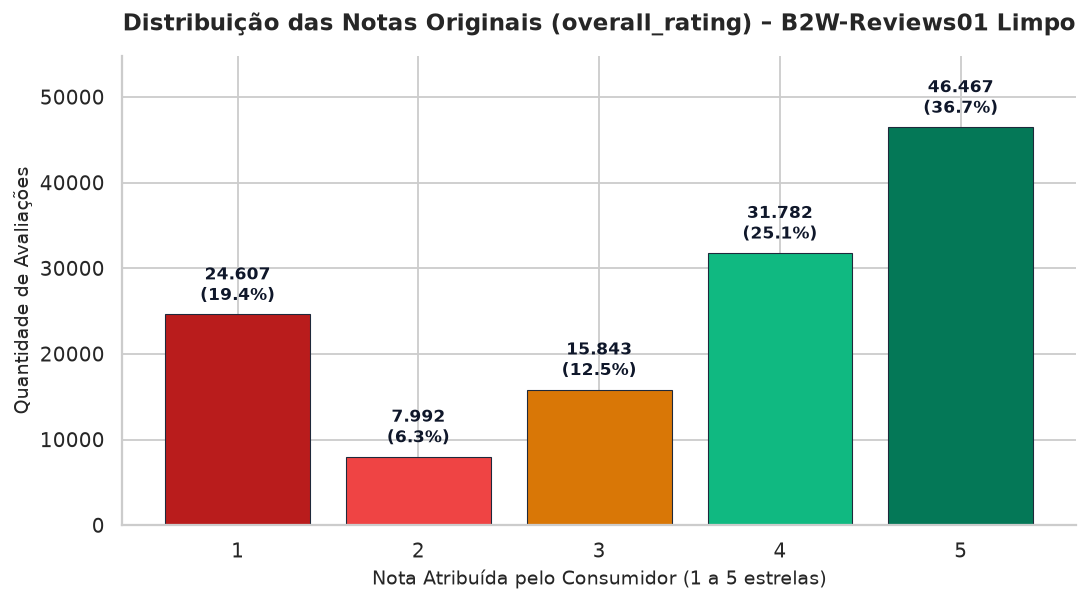

In [5]:
# Gráfico 1: Distribuição das notas originais (1 a 5)
rating_counts = df_clean["overall_rating"].value_counts().sort_index()
rating_pct = (rating_counts / len(df_clean)) * 100

fig, ax = plt.subplots(figsize=(8.5, 4.8))
bar_colors = ["#B91C1C", "#EF4444", "#D97706", "#10B981", "#047857"]
bars = ax.bar(rating_counts.index.astype(str), rating_counts.values, color=bar_colors, edgecolor="#1E293B", linewidth=0.6)

for bar, count, pct in zip(bars, rating_counts.values, rating_pct.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + len(df_clean) * 0.008,
        f"{count:,}\n({pct:.1f}%)".replace(",", "."),
        ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#0F172A"
    )

ax.set_title("Distribuição das Notas Originais (overall_rating) – B2W-Reviews01 Limpo", fontsize=12.5, fontweight="bold", pad=14)
ax.set_xlabel("Nota Atribuída pelo Consumidor (1 a 5 estrelas)", fontsize=10.5)
ax.set_ylabel("Quantidade de Avaliações", fontsize=10.5)
ax.set_ylim(0, rating_counts.max() * 1.18)
sns.despine()
plt.tight_layout()
fig.savefig(FIGURES_DIR / "01_distribuicao_notas.png", dpi=300)
plt.show()


Resumo comparativo – Cenário Binário (sem nota 3):
{'Positivo': 78249, 'Negativo': 32599} | Total: 110,848
Razão Positivo / Neutro no cenário 3 classes: 4.94x (forte desequilíbrio -> priorizar F1-Macro!)


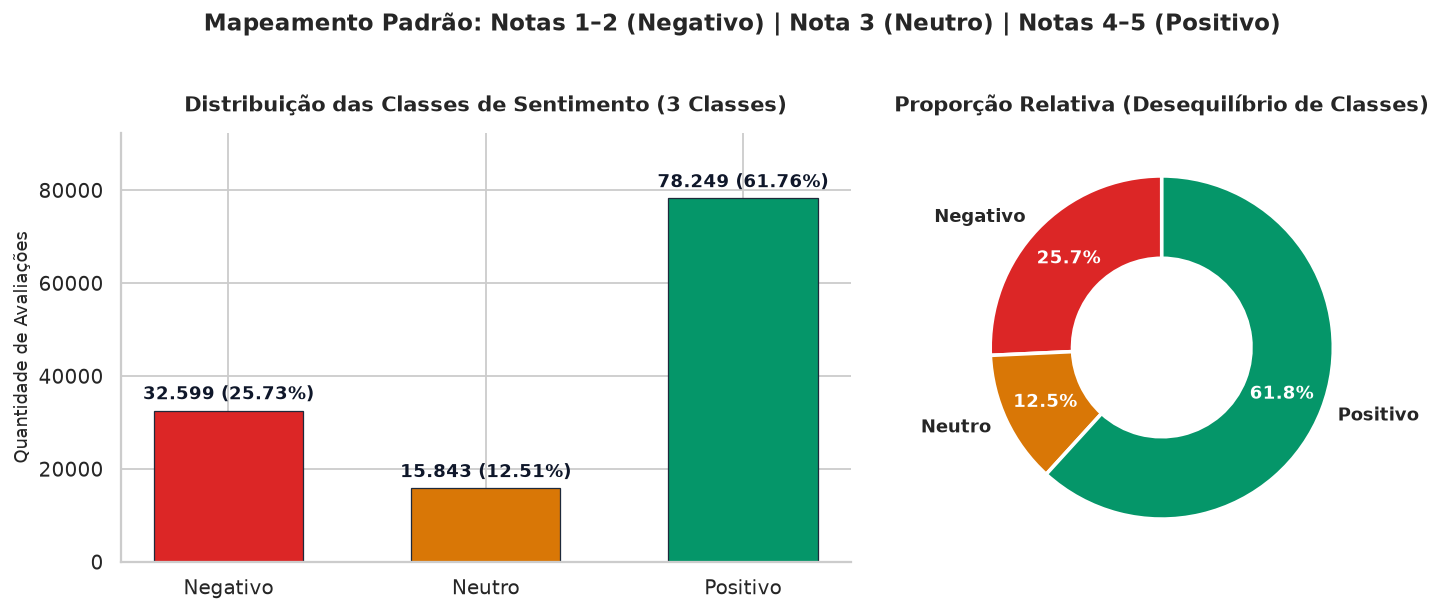

In [6]:
# Gráfico 2: Distribuição das 3 classes de sentimento (evidenciando desequilíbrio)
sent_counts = df_clean["sentiment"].value_counts().reindex(SENTIMENT_ORDER)
sent_pct = (sent_counts / len(df_clean)) * 100

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.4, 1.0]})

# Barras com quantidade e percentual
colors = [PALETTE_SENTIMENT[s] for s in SENTIMENT_ORDER]
bars = axes[0].bar(SENTIMENT_ORDER, sent_counts.values, color=colors, edgecolor="#1E293B", linewidth=0.7, width=0.58)
for bar, count, pct in zip(bars, sent_counts.values, sent_pct.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + len(df_clean) * 0.012,
        f"{count:,} ({pct:.2f}%)".replace(",", "."),
        ha="center", va="bottom", fontsize=9.8, fontweight="bold", color="#0F172A"
    )
axes[0].set_title("Distribuição das Classes de Sentimento (3 Classes)", fontsize=11.5, fontweight="bold", pad=12)
axes[0].set_ylabel("Quantidade de Avaliações", fontsize=10)
axes[0].set_ylim(0, sent_counts.max() * 1.18)
sns.despine(ax=axes[0])

# Donut chart proporcional
wedges, texts, autotexts = axes[1].pie(
    sent_counts.values,
    labels=SENTIMENT_ORDER,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    pctdistance=0.75,
    wedgeprops={"width": 0.48, "edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 10, "fontweight": "bold"},
)
for at in autotexts:
    at.set_color("white")
axes[1].set_title("Proporção Relativa (Desequilíbrio de Classes)", fontsize=11.5, fontweight="bold", pad=12)

plt.suptitle("Mapeamento Padrão: Notas 1–2 (Negativo) | Nota 3 (Neutro) | Notas 4–5 (Positivo)", fontsize=12.5, fontweight="bold", y=1.02)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "02_distribuicao_sentimentos.png", dpi=300, bbox_inches="tight")
plt.show()

# Comparação com cenário binário (excluindo nota 3)
df_bin, _ = clean_and_label_dataset(df_raw, rating_mapping=BINARY_SENTIMENT_MAP)
print("Resumo comparativo – Cenário Binário (sem nota 3):")
print(df_bin["sentiment"].value_counts().to_dict(), "| Total:", f"{len(df_bin):,}")
print(f"Razão Positivo / Neutro no cenário 3 classes: {sent_counts['Positivo'] / sent_counts['Neutro']:.2f}x (forte desequilíbrio -> priorizar F1-Macro!)")


---
## 4. Extensão das Avaliações por Classe de Sentimento

Analisar o tamanho dos textos (em palavras e caracteres) ajuda a compreender o comportamento dos consumidores: em e-commerce, avaliações **negativas** tendem a ser mais longas, pois o cliente detalha defeitos, atrasos ou problemas no atendimento, enquanto avaliações **positivas** costumam ser mais curtas e diretas (ex.: *"Ótimo produto, chegou antes do prazo"*).


,avaliacoes,media,desvio_padrao,minimo,mediana,p90,p95,maximo
sentiment,,,,,,,,
Negativo,32599,32.33,27.28,1,24.0,63.0,83.0,628
Neutro,15843,23.95,23.20,1,17.0,46.0,62.0,795
Positivo,78249,18.70,17.14,1,14.0,34.0,46.0,696


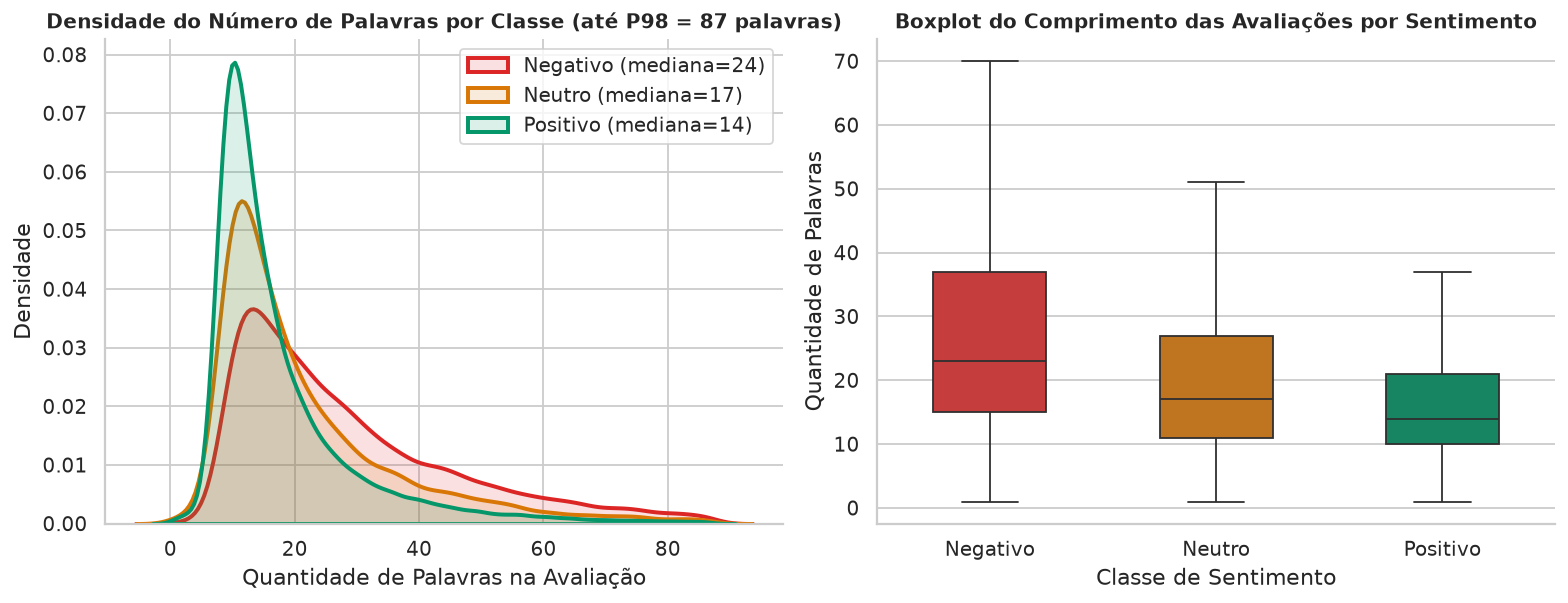

In [7]:
# Estatísticas descritivas do número de palavras por classe
length_stats = (
    df_clean.groupby("sentiment")["word_count"]
    .agg(
        avaliacoes="count",
        media="mean",
        desvio_padrao="std",
        minimo="min",
        mediana="median",
        p90=lambda s: np.percentile(s, 90),
        p95=lambda s: np.percentile(s, 95),
        maximo="max",
    )
    .reindex(SENTIMENT_ORDER)
    .round(2)
)
display(length_stats)

# Gráfico 3: Distribuição do tamanho das avaliações (até percentil 98 para visualização nítida)
p98 = int(np.percentile(df_clean["word_count"], 98))
df_plot = df_clean[df_clean["word_count"] <= p98]

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.8))

# Histograma / KDE por classe
for sent in SENTIMENT_ORDER:
    sub = df_plot[df_plot["sentiment"] == sent]["word_count"]
    sns.kdeplot(sub, ax=axes[0], label=f"{sent} (mediana={int(length_stats.loc[sent, 'mediana'])})", color=PALETTE_SENTIMENT[sent], linewidth=2.2, fill=True, alpha=0.14)
axes[0].set_title(f"Densidade do Número de Palavras por Classe (até P98 = {p98} palavras)", fontsize=10.8, fontweight="bold")
axes[0].set_xlabel("Quantidade de Palavras na Avaliação")
axes[0].set_ylabel("Densidade")
axes[0].legend(frameon=True)
sns.despine(ax=axes[0])

# Boxplot por classe
sns.boxplot(
    data=df_plot,
    x="sentiment",
    y="word_count",
    order=SENTIMENT_ORDER,
    hue="sentiment",
    palette=PALETTE_SENTIMENT,
    legend=False,
    showfliers=False,
    width=0.5,
    ax=axes[1],
)
axes[1].set_title("Boxplot do Comprimento das Avaliações por Sentimento", fontsize=10.8, fontweight="bold")
axes[1].set_xlabel("Classe de Sentimento")
axes[1].set_ylabel("Quantidade de Palavras")
sns.despine(ax=axes[1])

plt.tight_layout()
fig.savefig(FIGURES_DIR / "03_tamanho_avaliacoes.png", dpi=300)
plt.show()


---
## 5. Distribuição por Categorias de Produto (`site_category_lv1`)

Esta análise prepara diretamente a investigação solicitada na **Pergunta 5 da Seção 2.6** do edital (*"O desempenho se mantém em avaliações de produtos ou categorias diferentes?"*), mostrando quais categorias concentram mais avaliações e se há variação na taxa de sentimentos negativos entre elas.


sentiment,Negativo,Neutro,Positivo,Total,% Negativo,% Neutro,% Positivo
site_category_lv1,,,,,,,
Celulares e Smartphones,3867,2217,14007,20091,19.2,11.0,69.7
Eletroportáteis,1928,1382,8134,11444,16.8,12.1,71.1
Beleza e Perfumaria,2211,1059,5386,8656,25.5,12.2,62.2
Utilidades Domésticas,1949,1050,4900,7899,24.7,13.3,62.0
TV e Home Theater,1601,851,4876,7328,21.8,11.6,66.5
Informática e Acessórios,2227,870,4048,7145,31.2,12.2,56.7
Móveis,2913,1076,2645,6634,43.9,16.2,39.9
Brinquedos,1291,547,2680,4518,28.6,12.1,59.3
Casa e Construção,1386,581,2274,4241,32.7,13.7,53.6


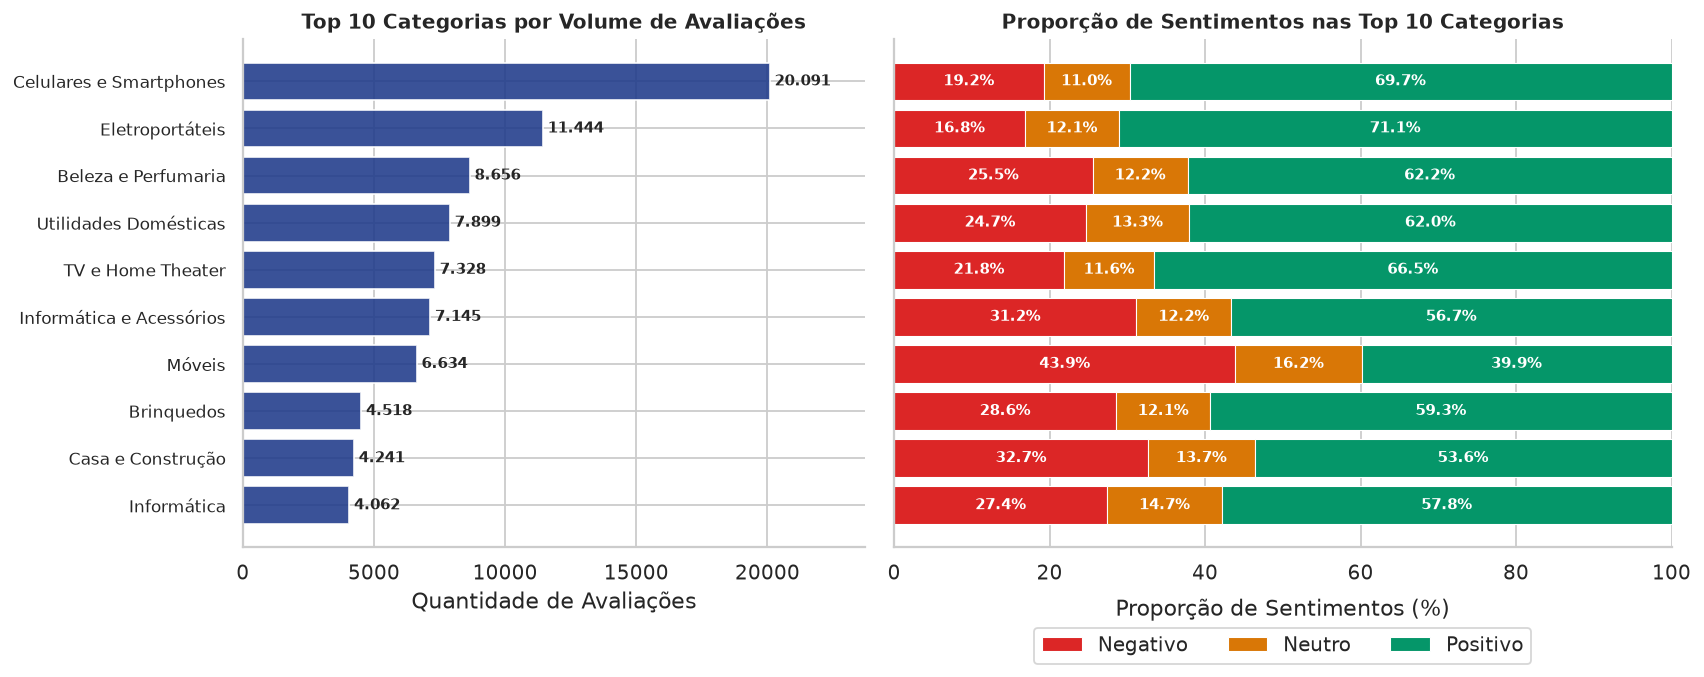

In [8]:
top10_cats = df_clean["site_category_lv1"].value_counts().head(10)
df_top10 = df_clean[df_clean["site_category_lv1"].isin(top10_cats.index)]

cat_pivot = pd.crosstab(df_top10["site_category_lv1"], df_top10["sentiment"])[SENTIMENT_ORDER]
cat_pivot = cat_pivot.loc[top10_cats.index]
cat_pct = cat_pivot.div(cat_pivot.sum(axis=1), axis=0) * 100

cat_summary = cat_pivot.copy()
cat_summary["Total"] = cat_pivot.sum(axis=1)
cat_summary["% Negativo"] = cat_pct["Negativo"].round(1)
cat_summary["% Neutro"] = cat_pct["Neutro"].round(1)
cat_summary["% Positivo"] = cat_pct["Positivo"].round(1)
display(cat_summary)

# Gráfico 4: Top 10 categorias (volume total + composição percentual de sentimentos)
fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.4), gridspec_kw={"width_ratios": [1.0, 1.25]})

# Esquerda: Volume
y_pos = np.arange(len(top10_cats))
axes[0].barh(y_pos, top10_cats.values[::-1], color="#1E3A8A", alpha=0.88)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(top10_cats.index[::-1], fontsize=9.2)
axes[0].set_title("Top 10 Categorias por Volume de Avaliações", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Quantidade de Avaliações")
for idx, val in enumerate(top10_cats.values[::-1]):
    axes[0].text(val + 180, idx, f"{val:,}".replace(",", "."), va="center", fontsize=8.5, fontweight="bold")
axes[0].set_xlim(0, top10_cats.max() * 1.18)
sns.despine(ax=axes[0])

# Direita: Barras empilhadas 100%
cat_pct_rev = cat_pct.iloc[::-1]
left = np.zeros(len(cat_pct_rev))
for sent in SENTIMENT_ORDER:
    vals = cat_pct_rev[sent].values
    axes[1].barh(y_pos, vals, left=left, label=sent, color=PALETTE_SENTIMENT[sent], edgecolor="white", linewidth=0.6)
    for i, v in enumerate(vals):
        if v >= 9.0:
            axes[1].text(left[i] + v / 2, i, f"{v:.1f}%", ha="center", va="center", color="white", fontsize=8.2, fontweight="bold")
    left += vals

axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([""] * len(y_pos))
axes[1].set_xlim(0, 100)
axes[1].set_xlabel("Proporção de Sentimentos (%)", labelpad=8)
axes[1].set_title("Proporção de Sentimentos nas Top 10 Categorias", fontsize=11, fontweight="bold")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=True)
sns.despine(ax=axes[1])

plt.tight_layout()
fig.savefig(FIGURES_DIR / "04_top_categorias.png", dpi=300, bbox_inches="tight")
plt.show()


---
## 6. Validação da Amostragem Estratificada e Exportação do Resumo (`eda_summary.json`)

Conforme a Seção 2.3 do edital, caso a equipe opte por rodar experimentos exploratórios mais rápidos em uma amostra estratificada (ex.: 30.000 avaliações), a proporção das notas e classes deve ser rigorosamente preservada. Abaixo validamos essa preservação e salvamos o resumo estruturado da EDA para a Pessoa 3 carregar na Aba 1 do Streamlit.


In [9]:
df_sample_30k = get_stratified_sample(df_clean, n_samples=30000, stratify_col="overall_rating", random_state=42)

comp_strat = pd.DataFrame({
    "Corpus Completo (%)": (df_clean["sentiment"].value_counts(normalize=True).reindex(SENTIMENT_ORDER) * 100).round(2),
    "Amostra Estratificada 30k (%)": (df_sample_30k["sentiment"].value_counts(normalize=True).reindex(SENTIMENT_ORDER) * 100).round(2),
    "Diferença (p.p.)": (
        (df_clean["sentiment"].value_counts(normalize=True).reindex(SENTIMENT_ORDER)
         - df_sample_30k["sentiment"].value_counts(normalize=True).reindex(SENTIMENT_ORDER)).abs() * 100
    ).round(4),
})
display(comp_strat)

# Exportar resumo consolidado em JSON para relatório e interface Streamlit (Pessoa 3)
eda_summary = {
    "dataset_metadata": DATASET_METADATA,
    "audit_cleaning_steps": audit["cleaning_steps"],
    "personal_columns_removed": audit["personal_columns_removed"],
    "conflicting_rating_texts": audit["conflicting_rating_texts"],
    "inconsistent_neg_rating_yes_recommend": int(len(incons_neg_yes)),
    "inconsistent_pos_rating_no_recommend": int(len(incons_pos_no)),
    "clean_rating_distribution": audit["clean_rating_distribution"],
    "clean_sentiment_distribution": audit["clean_sentiment_distribution"],
    "clean_sentiment_pct": audit["clean_sentiment_pct"],
    "word_count_stats_by_sentiment": length_stats.to_dict(orient="index"),
    "top10_categories": {
        cat: {
            "total": int(cat_summary.loc[cat, "Total"]),
            "pct_negativo": float(cat_summary.loc[cat, "% Negativo"]),
            "pct_neutro": float(cat_summary.loc[cat, "% Neutro"]),
            "pct_positivo": float(cat_summary.loc[cat, "% Positivo"]),
        }
        for cat in cat_summary.index
    },
    "date_range": {
        "min": str(df_clean["submission_date"].min()),
        "max": str(df_clean["submission_date"].max()),
    },
}

summary_path = REPORTS_DIR / "eda_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(eda_summary, f, ensure_ascii=False, indent=2)

print(f"[OK] Resumo da EDA salvo em: {summary_path}")
print(f"[OK] 4 gráficos salvos em: {FIGURES_DIR}")


[OK] Resumo da EDA salvo em: C:\Users\Guilherme\Documents\IA\projeto\reports\eda_summary.json
[OK] 4 gráficos salvos em: C:\Users\Guilherme\Documents\IA\projeto\reports\figures


,Corpus Completo (%),Amostra Estratificada 30k (%),Diferença (p.p.)
sentiment,,,
Negativo,25.73,25.73,0.0011
Neutro,12.51,12.51,0.0014
Positivo,61.76,61.76,0.0003
